# Behavioral Pattern, notebook 3: how often each rule fires, and agreement with the assistant labels

Both threshold sets, side by side. Agreement is a **pipeline check**: the labels were written by the assistant with the same kind of reasoning as the rules, so agreement shows the
rules implement the idea, not that they match instructors. Agreement is also reported only on the student-sprints where Collaboration is available (otherwise the two rules
that need it cannot fire by design).

In [1]:
import sys, warnings, json, importlib.util
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score, confusion_matrix
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
ROOT = Path("../../..").resolve()
spec = importlib.util.spec_from_file_location("bp_rules_nb", ROOT / "rules.py")
R = importlib.util.module_from_spec(spec); spec.loader.exec_module(R)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
d = pd.read_csv(Path("../../dataset/bp_inputs.csv"))
PATTERNS = list(R.PATTERNS) + ["Balanced contributor"]
def run(thresholds, frame=None):
    frame = d if frame is None else frame
    out = []
    for r in frame.itertuples():
        co = None if pd.isna(r.Co) else float(r.Co)
        bim = None if pd.isna(r.bimodal) else int(r.bimodal)
        lc = None if pd.isna(r.late_churn) else float(r.late_churn)
        out.append(R.classify({"E": float(r.E), "C": float(r.C), "Co": co}, bim, thresholds, lc))
    return out

In [2]:
SETS = {"proposal": R.load_thresholds("proposal"), "calibrated_v1": R.load_thresholds("calibrated_v1"), "calibrated_AB": R.load_thresholds("calibrated_AB"), "calibrated": R.load_thresholds("calibrated")}
OUT = {}
for name, th in SETS.items():
    res = run(th)
    OUT[name] = pd.Series([r["persona"] for r in res], name=name)
    d[f"pattern_{name}"] = OUT[name].values
    d[f"mod_{name}"] = [r["score_modifier"] for r in res]
fire = pd.DataFrame({n: o.value_counts() for n, o in OUT.items()}).reindex(PATTERNS + ["Unclassified"]).fillna(0).astype(int)
fire["old rules in the dataset"] = d.rule_pattern_old.value_counts().reindex(fire.index).fillna(0).astype(int)
fire

,proposal,calibrated_v1,calibrated_AB,calibrated,old rules in the dataset
Consistent deep contributor,2,57,50,57,27
Last-minute rusher,1,0,39,0,3
Reviewer or coordinator,7,6,6,6,14
Burst worker,2,4,4,4,3
Free rider,26,15,61,61,96
Balanced contributor,281,237,159,191,176
Unclassified,0,0,0,0,0


Firing by source and by whether Collaboration was available:

In [3]:
for name in SETS:
    print(name); print(pd.crosstab(d[f"pattern_{name}"], [d.source, d.Co_available]).reindex(PATTERNS + ["Unclassified"]).fillna(0).astype(int))

proposal
source                       real       simulated      
Co_available                False True      False True 
pattern_proposal                                       
Consistent deep contributor     1     0         0     1
Last-minute rusher              0     1         0     0
Reviewer or coordinator         0     0         0     7
Burst worker                    2     0         0     0
Free rider                      0     0         0    26
Balanced contributor          133     7        50    91
Unclassified                    0     0         0     0
calibrated_v1


source                       real       simulated      
Co_available                False True      False True 
pattern_calibrated_v1                                  
Consistent deep contributor    29     2         6    20
Last-minute rusher              0     0         0     0
Reviewer or coordinator         0     0         0     6
Burst worker                    3     0         1     0
Free rider                      0     0         0    15
Balanced contributor          104     6        43    84
Unclassified                    0     0         0     0
calibrated_AB
source                       real       simulated      
Co_available                False True      False True 
pattern_calibrated_AB                                  
Consistent deep contributor    23     2         6    19
Last-minute rusher             18     2         7    12
Reviewer or coordinator         0     0         0     6
Burst worker                    3     0         1     0
Free rider                     41 

## Agreement with the assistant labels

In [4]:
def agree(pred, truth, label):
    m = truth.notna()
    p, t = pred[m], truth[m]
    cm = confusion_matrix(t, p, labels=PATTERNS)
    rec = {k: (cm[i, i] / cm[i].sum() if cm[i].sum() else np.nan) for i, k in enumerate(PATTERNS)}
    prec = {k: (cm[i, i] / cm[:, i].sum() if cm[:, i].sum() else np.nan) for i, k in enumerate(PATTERNS)}
    return {"labels": label, "n": int(m.sum()), "accuracy": float((p == t).mean()), "kappa": float(cohen_kappa_score(t, p)), "recall": rec, "precision": prec, "confusion": cm}
rows, details = [], {}
for name in SETS:
    for label, col, mask in (("simulated classes (all)", "sim_class", d.index == d.index), ("reference pattern (all)", "ref_pattern", d.index == d.index), ("reference pattern, Collaboration available", "ref_pattern", d.Co_available),
                             ("anchors (20)", "gt_pattern", d.index == d.index)):
        sub = d[mask]
        a = agree(sub[f"pattern_{name}"], sub[col], label)
        details[(name, label)] = a
        rows.append({"thresholds": name, **{k: a[k] for k in ("labels", "n", "accuracy", "kappa")}})
ag = pd.DataFrame(rows).round(3)
ag.to_csv(RESULTS / "agreement.csv", index=False)
ag

,thresholds,labels,n,accuracy,kappa
0,proposal,simulated classes (all),175,0.314,0.142
1,proposal,reference pattern (all),299,0.197,0.059
2,proposal,"reference pattern, Collaboration available",131,0.252,0.132
3,proposal,anchors (20),20,0.200,0.000
4,calibrated_v1,simulated classes (all),175,0.417,0.274
5,calibrated_v1,reference pattern (all),299,0.328,0.206
6,calibrated_v1,"reference pattern, Collaboration available",131,0.412,0.308
7,calibrated_v1,anchors (20),20,0.400,0.250
8,calibrated_AB,simulated classes (all),175,0.491,0.371
9,calibrated_AB,reference pattern (all),299,0.485,0.385


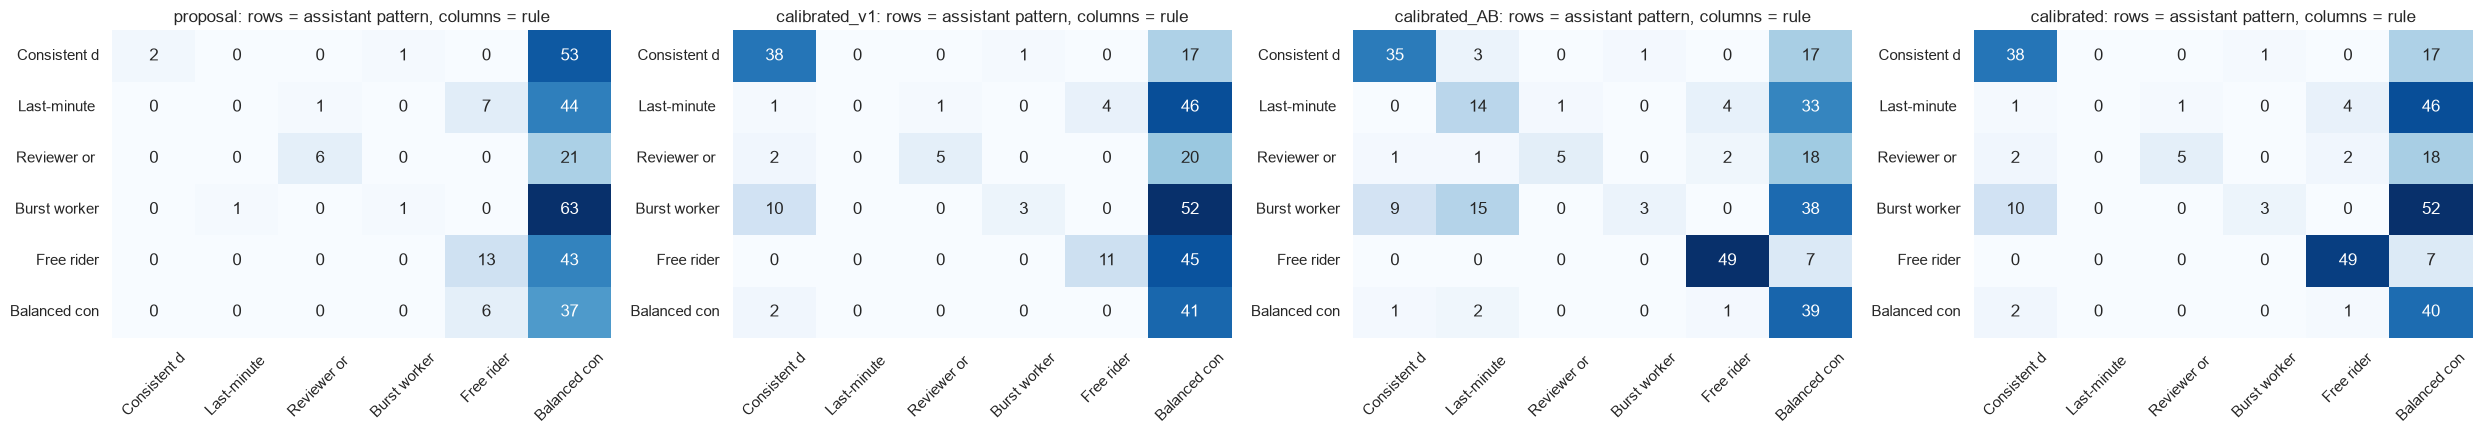

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(25, 4.5))
for ax, name in zip(axes, SETS):
    a = details[(name, "reference pattern (all)")]
    sns.heatmap(a["confusion"], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=[p[:12] for p in PATTERNS], yticklabels=[p[:12] for p in PATTERNS])
    ax.set_title(f"{name}: rows = assistant pattern, columns = rule"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [6]:
rec = pd.DataFrame({name: pd.Series(details[(name, "reference pattern (all)")]["recall"]) for name in SETS}).round(2)
prec = pd.DataFrame({name: pd.Series(details[(name, "reference pattern (all)")]["precision"]) for name in SETS}).round(2)
print("recall per pattern (reference pattern, all records)"); print(rec); print("precision per pattern"); print(prec)
d.to_csv(RESULTS / "patterns_by_record.csv", index=False)

recall per pattern (reference pattern, all records)
                             proposal  calibrated_v1  calibrated_AB  calibrated
Consistent deep contributor      0.04           0.68           0.62        0.68
Last-minute rusher               0.00           0.00           0.27        0.00
Reviewer or coordinator          0.22           0.19           0.19        0.19
Burst worker                     0.02           0.05           0.05        0.05
Free rider                       0.23           0.20           0.88        0.88
Balanced contributor             0.86           0.95           0.91        0.93
precision per pattern
                             proposal  calibrated_v1  calibrated_AB  calibrated
Consistent deep contributor      1.00           0.72           0.76        0.72
Last-minute rusher               0.00            NaN           0.40         NaN
Reviewer or coordinator          0.86           0.83           0.83        0.83
Burst worker                     0.50         

## Keep or revert the two extensions (criteria fixed in the protocol before they were implemented)

A: on the **simulated** records (the extension was designed on the real ones) Last-minute rusher recall at least 0.30 and precision at least 0.50, and no other pattern loses more than 0.05 recall against `calibrated_v1`.
B: Free rider recall on all labelled records rises and its precision stays at least 0.60.

In [7]:
def rp(col, mask, sets=("calibrated_v1", "calibrated_AB", "calibrated")):
    out = {}
    sub = d[mask]
    for name in sets:
        a = agree(sub[f"pattern_{name}"], sub[col], name)
        out[name] = a
    return out
sim_m = d.source == "simulated"
A = rp("sim_class", sim_m)
allm = d.index == d.index
B = rp("ref_pattern", allm)
ru = "Last-minute rusher"
rec = lambda a, k: a["recall"][k]; prc = lambda a, k: a["precision"][k]
a_ok_rusher = rec(A["calibrated_AB"], ru) >= 0.30 and (prc(A["calibrated_AB"], ru) >= 0.50)
a_others = {k: rec(A["calibrated_AB"], k) - rec(A["calibrated_v1"], k) for k in PATTERNS if k != ru}
a_ok_others = all(v >= -0.05 for v in a_others.values())
fr = "Free rider"
b_ok = rec(B["calibrated_AB"], fr) > rec(B["calibrated_v1"], fr) and prc(B["calibrated_AB"], fr) >= 0.60
res = {"A rusher recall (simulated)": round(float(rec(A["calibrated_AB"], ru)), 3), "A rusher precision (simulated)": round(float(prc(A["calibrated_AB"], ru)), 3) if prc(A["calibrated_AB"], ru) == prc(A["calibrated_AB"], ru) else None,
       "A other patterns' recall change (simulated)": {k: round(float(v), 3) for k, v in a_others.items()}, "A kept": bool(a_ok_rusher and a_ok_others),
       "B free rider recall v1 -> with B (all labelled)": [round(float(rec(B["calibrated_v1"], fr)), 3), round(float(rec(B["calibrated_AB"], fr)), 3)], "B free rider precision with B": round(float(prc(B["calibrated_AB"], fr)), 3), "B kept": bool(b_ok)}
(RESULTS / "extension_decision.json").write_text(json.dumps(res, indent=1), encoding="utf-8")
res

{'A rusher recall (simulated)': 0.3,
 'A rusher precision (simulated)': 0.474,
 "A other patterns' recall change (simulated)": {'Consistent deep contributor': 0.0,
  'Reviewer or coordinator': 0.0,
  'Burst worker': 0.0,
  'Free rider': 0.143,
  'Balanced contributor': 0.0},
 'A kept': False,
 'B free rider recall v1 -> with B (all labelled)': [0.196, 0.875],
 'B free rider precision with B': 0.875,
 'B kept': True}

## What do the labelled patterns look like in the scores?

Why the rules miss some patterns: the typical scores of the records the assistant gave each pattern, against the rule thresholds.

In [8]:
diag = d.groupby("ref_pattern").agg(n=("E", "size"), E_median=("E", "median"), C_median=("C", "median"), C_p25=("C", lambda x: x.quantile(0.25)),
                                   Co_available=("Co_available", "mean"), Co_median=("Co", "median"), bimodal_share=("bimodal", "mean")).round(3)
diag.to_csv(RESULTS / "label_profiles.csv")
diag

,n,E_median,C_median,C_p25,Co_available,Co_median,bimodal_share
ref_pattern,,,,,,,
Balanced contributor,43,0.324,0.331,0.248,0.442,0.250,0.140
Burst worker,65,0.492,0.330,0.270,0.354,0.250,0.323
Consistent deep contributor,56,0.583,0.544,0.467,0.482,0.250,0.018
Free rider,56,0.021,0.000,0.000,0.232,0.000,0.000
Last-minute rusher,52,0.358,0.210,0.124,0.519,0.250,0.019
Reviewer or coordinator,27,0.362,0.204,0.028,0.815,0.732,0.111


## Reading the results

**Firing (319 student-sprints).** With the proposal's cut points almost nothing fires: 2 Consistent deep contributor, 1 Last-minute rusher, 7 Reviewer or coordinator, 2 Burst worker, 26 Free rider, 281 Balanced. The final calibrated set (original rules plus the effort-only Free rider path) gives 57, 0, 6, 4, 61 and 191. The old rules in the dataset fired Free rider 96 times.

**Agreement with the assistant labels** (a pipeline check only; the labels come from the same kind of reasoning as the rules, so this is not instructor validation):

| Thresholds | simulated classes (accuracy, kappa) | reference pattern, all | reference pattern, Collaboration available | 20 anchors |
|---|---|---|---|---|
| proposal | 0.31, 0.14 | 0.20, 0.06 | 0.25, 0.13 | 0.20, 0.00 |
| calibrated v1 (original rules) | 0.42, 0.27 | 0.33, 0.21 | 0.41, 0.31 | 0.40, 0.25 |
| **calibrated (adopted: + effort-only Free rider)** | 0.44, 0.30 | 0.45, 0.35 | 0.41, 0.31 | 0.65, 0.56 |
| calibrated AB (both extensions, not adopted) | 0.49, 0.37 | 0.49, 0.39 | 0.46, 0.36 | 0.80, 0.74 |

**Per pattern (adopted set, all labelled records).** Consistent deep contributor: recall 0.68, precision 0.72. Reviewer or coordinator: recall 0.19, precision 0.83. Burst worker: recall 0.05, precision 0.75. Free rider: recall 0.88, precision 0.88. Last-minute rusher: never fires (recall 0). When a rule fires it is usually right; two of the five patterns still fire rarely or never.

**The two extensions, judged by the criteria written before they were implemented.** Extension B (Free rider on effort alone when Collaboration is not available) raised Free rider recall from 0.20 to 0.88 at precision 0.88: adopted. Extension A (a second path to Last-minute rusher through the late-churn share `C_DC`) reached recall 0.30 and precision 0.47 on the simulated records, where the criteria asked for at least 0.30 and 0.50: not adopted, by 0.03. Had both been kept, accuracy would be higher (0.49 on the simulated classes, 0.80 on the anchors), but that figure also includes the records Extension A was designed on, so it is the optimistic one.

**Why the remaining misses.** The records labelled Last-minute rusher have a median Effort of 0.36 and a median Consistency of 0.21 (the rule needs Effort above 0.54 and Consistency below 0.05). The Effort and Consistency marks do not separate a rusher from a balanced contributor by thresholds alone. Labelled Burst workers have the bimodal flag in only 32% of cases, and 65 records carry that label against 4 that the rule finds.

**What this means.** The rules are implemented as specified and behave consistently; read on this data, the proposal's rules find Consistent deep contributors, strong reviewers and (with the effort-only path) non-contributors, and miss rushers and burst workers because of how the underlying scores are distributed. Whether instructors would call these records rushers or burst workers is what the instructor study of the proposal has to answer.
